In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from retail_demand_forecasting.data import load_sales, time_split
from retail_demand_forecasting.metrics import mae, wape, bias
from retail_demand_forecasting.baselines import BASELINES

df = load_sales("../data/raw/train.csv")
train, test = time_split(df, "2017-10-01")
print(len(train), len(test))

867000 46000


In [7]:
rows, preds = [], {}
for name, f in BASELINES.items():
    pred = f(train, test)
    preds[name] = pred
    rows.append({
        "model": name,
        "MAE": mae(test["sales"], pred),
        "WAPE": wape(test["sales"], pred),
        "Bias": bias(test["sales"], pred),
    })

results = pd.DataFrame(rows).set_index("model").sort_values("WAPE")
results.round(3)

,MAE,WAPE,Bias
model,,,
yearly_seasonal_growth,8.349,0.153,-0.002
weekly_average_4w,10.847,0.198,0.136
seasonal_naive_weekly,12.017,0.220,0.135
naive_last,17.200,0.315,0.266


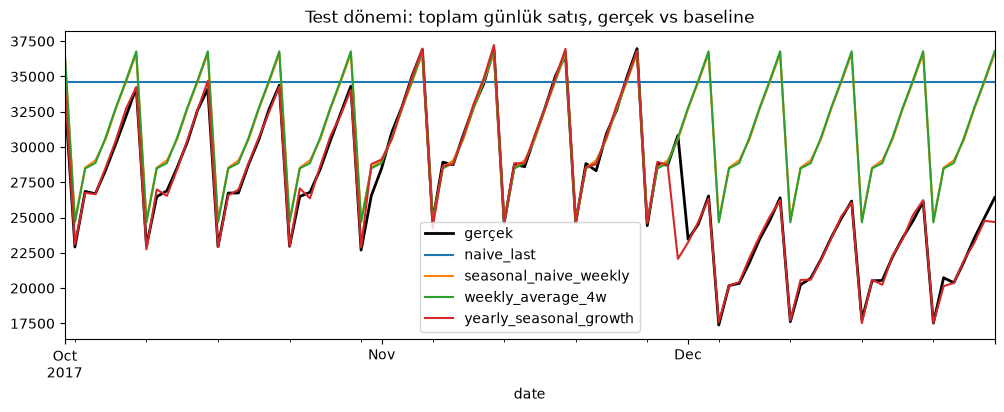

In [8]:
actual = test.groupby("date")["sales"].sum()

plt.figure(figsize=(12, 4))
actual.plot(label="gerçek", color="black", linewidth=2)
for name, pred in preds.items():
    pred.groupby(test["date"]).sum().plot(label=name)
plt.legend()
plt.title("Test dönemi: toplam günlük satış, gerçek vs baseline")
plt.show()

In [9]:
err = pd.DataFrame({n: (test["sales"] - p).abs() for n, p in preds.items()})
month = test["date"].dt.month
by_month = err.groupby(month).sum().div(test.groupby(month)["sales"].sum(), axis=0)
by_month.round(3)

,naive_last,seasonal_naive_weekly,weekly_average_4w,yearly_seasonal_growth
date,,,,
10,0.252,0.158,0.132,0.149
11,0.199,0.138,0.110,0.145
12,0.549,0.407,0.402,0.168
